# 用 DALL·E 和 Segment Anything 建立動態 mask

> 原文：[examples/dalle/How_to_create_dynamic_masks_with_DALL-E_and_Segment_Anything.ipynb](https://github.com/openai/openai-cookbook/blob/main/examples/dalle/How_to_create_dynamic_masks_with_DALL-E_and_Segment_Anything.ipynb)



## 這篇在做什麼
先用 DALL·E 生成一張圖，再用 Meta 的 Segment Anything (SAM) 在圖上「點一下」選出要改的區域，產生 mask。最後把 mask 丟給 DALL·E 的 Edit endpoint，用新的 prompt 重畫被遮住的部分。範例情境是幫數位模特兒換衣服。

## 學完你會
- 安裝並載入 SAM，用點擊座標產生圖片 mask。
- 把 mask 轉成 DALL·E Edit endpoint 要的透明區域格式。
- 用新的 prompt 對圖片局部做 inpainting。

## 開跑前
- 需要 OpenAI API key，並能使用 dall-e-2 的 edit。
- 需要下載 SAM 的 model checkpoint（預設約 2.4 GB）。
- 在 Colab 上跑的話，pip 指令前加 `!`，checkpoint 可以用 `wget` 下載到 runtime，GPU runtime 會讓 SAM 快很多。

In [ ]:
# 環境設定：在 Colab 左側 🔑 Secrets 新增 OPENAI_API_KEY
%pip install -q -U git+https://github.com/facebookresearch/segment-anything.git matplotlib numpy openai opencv-python pillow requests torch
import os
try:
    from google.colab import userdata
    os.environ['OPENAI_API_KEY'] = userdata.get('OPENAI_API_KEY')
except ImportError:
    pass  # 本機執行就用自己的環境變數

# 抓原 repo 的資料檔（只下載這個資料夾）
if not os.path.exists('openai-cookbook'):
    !git clone -q --depth 1 --filter=blob:none --sparse https://github.com/openai/openai-cookbook
    !cd openai-cookbook && git sparse-checkout set examples/dalle
os.chdir('openai-cookbook/examples/dalle')

# 用 DALL·E 和 Segment Anything 建立動態 mask

Segment Anything 是 Meta 的模型，可以用來選取圖片的部分區域。搭配 DALL·E 對指定區域做 inpainting 的能力，你可以用 Segment Anything 輕鬆選出圖片中任何想修改的部分。

這份 notebook 會用這些工具來當時裝設計師，把數位模特兒的服裝動態換成量身打造的原創設計。流程如下：
- **Setup：** 初始化 library 和需要的資料夾位置。
- **生成原始圖片：** 做一張原始圖片，之後用它來建立動態 mask。
- **生成 mask：** 用 Segment Anything 建立動態 mask。
- **建立新圖片：** 用新的 prompt 對 mask 區域做 inpainting，生成新圖。

## Setup

首先要照 Meta 開源的 Segment Anything (SAM) 模型的[說明](https://github.com/facebookresearch/segment-anything)來設定。截至 2023 年 5 月，主要步驟是：
- 安裝 [Pytorch](https://pytorch.org/get-started/locally/)（1.7 以上版本）。
- 用 ```pip install git+https://github.com/facebookresearch/segment-anything.git``` 安裝 library。
- 用 ```pip install opencv-python pycocotools matplotlib onnxruntime onnx``` 安裝相依套件。
- 下載要用的 [model checkpoint](https://github.com/facebookresearch/segment-anything#model-checkpoints)（預設大小是 2.4 GB）。


In [ ]:
!pip install torch torchvision torchaudio
!pip install git+https://github.com/facebookresearch/segment-anything.git
!pip install opencv-python pycocotools matplotlib onnxruntime onnx
!pip install requests
!pip install openai
!pip install numpy

In [ ]:
!wget https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth

In [3]:
import cv2
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from matplotlib import rcParams
import numpy as np
from openai import OpenAI
import os
from PIL import Image
import requests
from segment_anything import sam_model_registry, SamAutomaticMaskGenerator, SamPredictor
import torch

# Set directories for generation images and edit images
base_image_dir = os.path.join("images", "01_generations")
mask_dir = os.path.join("images", "02_masks")
edit_image_dir = os.path.join("images", "03_edits")

# Point to your downloaded SAM model
sam_model_filepath = "./sam_vit_h_4b8939.pth"

# Initiate SAM model
sam = sam_model_registry["default"](checkpoint=sam_model_filepath)

# Initiate openAI client
client = OpenAI(api_key=os.environ.get("OPENAI_API_KEY", "<your OpenAI API key if not set as env var>"))


## 生成原始圖片

先做一張原始圖片，之後用它來生成 mask。

In [4]:
def process_dalle_images(response, filename, image_dir):
    # save the images
    urls = [datum.url for datum in response.data]  # extract URLs
    images = [requests.get(url).content for url in urls]  # download images
    image_names = [f"{filename}_{i + 1}.png" for i in range(len(images))]  # create names
    filepaths = [os.path.join(image_dir, name) for name in image_names]  # create filepaths
    for image, filepath in zip(images, filepaths):  # loop through the variations
        with open(filepath, "wb") as image_file:  # open the file
            image_file.write(image)  # write the image to the file

    return filepaths

In [5]:
dalle_prompt = '''
Full length, zoomed out photo of our premium Lederhosen-inspired jumpsuit.
Showcase the intricate hand-stitched details and high-quality leather, while highlighting the perfect blend of Austrian heritage and modern fashion.
This piece appeals to a sophisticated, trendsetting audience who appreciates cultural fusion and innovative design.
'''

In [6]:
# Generate your images
generation_response = client.images.generate(
    model = "dall-e-3",
    prompt=dalle_prompt,
    n=3,
    size="1024x1024",
    response_format="url",
)

In [8]:
filepaths = process_dalle_images(generation_response, "generation", base_image_dir)

In [ ]:
# print the new generations
for filepath in filepaths:
    print(filepath)
    display(Image.open(filepath))

## 生成 Mask

接著載入其中一張圖片來生成 mask。

這個示範選的操作方式是在圖片上「點」一個位置，從那個點生成 mask。Meta 另外提供了[範例 notebook](https://github.com/facebookresearch/segment-anything/blob/main/notebooks/automatic_mask_generator_example.ipynb)，示範如何生成圖片所有可能的 mask、框選範圍，還有其他實用做法。

In [10]:
# Pick one of your generated images
chosen_image = "images/01_generations/generation_2.png"

In [11]:
# Function to display mask using matplotlib
def show_mask(mask, ax):
    color = np.array([30 / 255, 144 / 255, 255 / 255, 0.6])
    h, w = mask.shape[-2:]
    mask_image = mask.reshape(h, w, 1) * color.reshape(1, 1, -1)
    ax.imshow(mask_image)


# Function to display where we've "clicked"
def show_points(coords, labels, ax, marker_size=375):
    pos_points = coords[labels == 1]
    neg_points = coords[labels == 0]
    ax.scatter(
        pos_points[:, 0],
        pos_points[:, 1],
        color="green",
        marker="*",
        s=marker_size,
        edgecolor="white",
        linewidth=1.25,
    )
    ax.scatter(
        neg_points[:, 0],
        neg_points[:, 1],
        color="red",
        marker="*",
        s=marker_size,
        edgecolor="white",
        linewidth=1.25,
    )


In [12]:
# Load chosen image using opencv
image = cv2.imread(chosen_image)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Display our chosen image
plt.figure(figsize=(10, 10))
plt.imshow(image)
plt.axis("on")
plt.show()

In [13]:
# Set the pixel coordinates for our "click" to assign masks
input_point = np.array([[525, 325]])
input_label = np.array([1])

# Display the point we've clicked on
plt.figure(figsize=(10, 10))
plt.imshow(image)
show_points(input_point, input_label, plt.gca())
plt.axis("on")
plt.show()

In [14]:
# Initiate predictor with Segment Anything model
predictor = SamPredictor(sam)
predictor.set_image(image)

# Use the predictor to gather masks for the point we clicked
masks, scores, logits = predictor.predict(
    point_coords=input_point,
    point_labels=input_label,
    multimask_output=True,
)

# Check the shape - should be three masks of the same dimensions as our image
masks.shape

(3, 1024, 1024)

In [15]:
# Display the possible masks we can select along with their confidence
for i, (mask, score) in enumerate(zip(masks, scores)):
    plt.figure(figsize=(10, 10))
    plt.imshow(image)
    show_mask(mask, plt.gca())
    show_points(input_point, input_label, plt.gca())
    plt.title(f"Mask {i+1}, Score: {score:.3f}", fontsize=18)
    plt.axis("off")
    plt.show()

In [16]:
# Choose which mask you'd like to use
chosen_mask = masks[1]

# We'll now reverse the mask so that it is clear and everything else is white
chosen_mask = chosen_mask.astype("uint8")
chosen_mask[chosen_mask != 0] = 255
chosen_mask[chosen_mask == 0] = 1
chosen_mask[chosen_mask == 255] = 0
chosen_mask[chosen_mask == 1] = 255


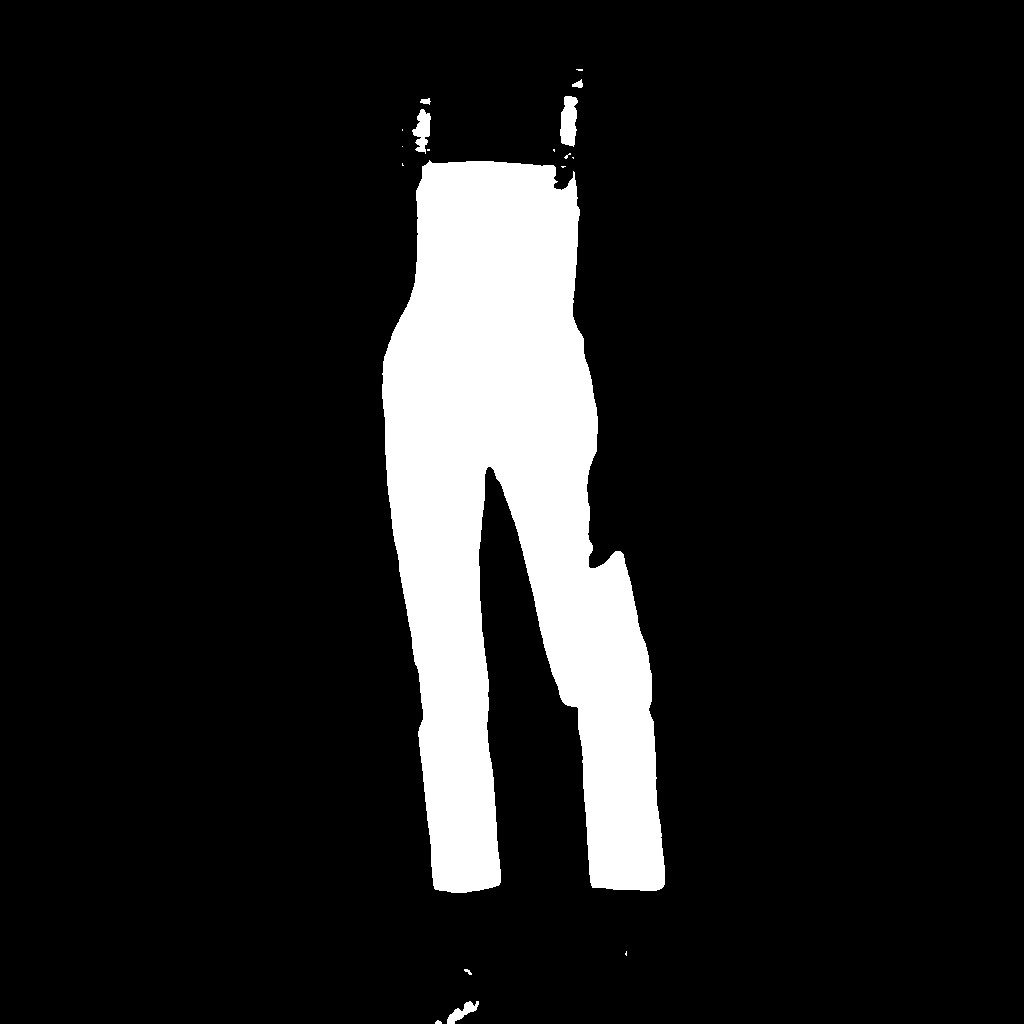

In [17]:
# create a base blank mask
width = 1024
height = 1024
mask = Image.new("RGBA", (width, height), (0, 0, 0, 1))  # create an opaque image mask

# Convert mask back to pixels to add our mask replacing the third dimension
pix = np.array(mask)
pix[:, :, 3] = chosen_mask

# Convert pixels back to an RGBA image and display
new_mask = Image.fromarray(pix, "RGBA")
new_mask

In [18]:
# We'll save this mask for re-use for our edit
new_mask.save(os.path.join(mask_dir, "new_mask.png"))

## 建立新圖片

現在把原始圖片、mask 和 DALL·E 的 Edit endpoint 結合起來，依新的 prompt 對透明區域做 inpainting。（截至 2024 年 1 月，只有 dall-e-2 支援 edit）


In [20]:
# edit an image
edit_response = client.images.edit(
    image=open(chosen_image, "rb"),  # from the generation section
    mask=open(os.path.join(mask_dir, "new_mask.png"), "rb"),  # from right above
    prompt="Brilliant leather Lederhosen with a formal look, detailed, intricate, photorealistic",  # provide a prompt to fill the space
    n=3,
    size="1024x1024",
    response_format="url",
)

edit_filepaths = process_dalle_images(edit_response, "edits", edit_image_dir)


In [21]:
# Display your beautiful creations!
%matplotlib inline

# figure size in inches optional
rcParams["figure.figsize"] = 11 ,8

# read images
img_A = mpimg.imread(edit_filepaths[0])
img_B = mpimg.imread(edit_filepaths[1])
img_C = mpimg.imread(edit_filepaths[2])

# display images
fig, ax = plt.subplots(1,3)
[a.axis("off") for a in ax]
ax[0].imshow(img_A)
ax[1].imshow(img_B)
ax[2].imshow(img_C)

太棒了！

現在你也能輕鬆建立動態 mask 來延伸你的圖片，好好玩這些 API，也歡迎分享你做了什麼！

## 重點整理
- SAM 負責「選哪裡」，DALL·E 負責「那裡畫什麼」，兩個模型分工。
- 點擊式 prompt 是最簡單的 SAM 用法，也可以改成框選或自動產生全部 mask。
- DALL·E 的 Edit endpoint 把圖片中透明的區域當成要重畫的範圍。
- 目前只有 dall-e-2 支援 edit，這會隨 API 更新改變。

## 練習
1. 改掉點擊的座標，選圖片中不同的部位生成 mask，看選到什麼。
2. 對同一個 mask 換三個不同的 inpainting prompt，比較結果。
3. 把點擊式 prompt 改成框選（box prompt），看 mask 的範圍有什麼不同。